# Model 1 - Random forest + lottery

**The starting point.** A random forest (200 decision trees) trained on a training set balanced by the **lottery**: random undersampling of stayers.

| Step | What happens |
|---|---|
| Label | blank `termination_date` = stayed (0), a date = left (1) |
| Split | 80/20, stratified, **before** the lottery so the test set stays untouched |
| Prepare | fill blanks (median / most frequent), scale numbers, one-hot encode categories |
| **Lottery** | randomly drop stayers in the training set until leavers are 45% as many as stayers |
| Model | random forest, 200 trees |
| Decision | flag an employee as a likely leaver if predicted probability >= **0.45** (a fixed number) |

This notebook is the *old* model. The next notebook (`02_logistic_regression_lottery`) changes the algorithm and the way the threshold is chosen.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.metrics import (classification_report, confusion_matrix, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, roc_curve)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

## 1. Load the data and create the target

In [2]:
NAME = "employee_churn_ecommerce_retail_5000_10cols.csv"      # original data (12.3% churn). Swap in the augmented CSV to experiment.
candidates = [Path(NAME), Path("data") / NAME, Path("..") / "data" / NAME, Path("..") / NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Could not find {NAME}. Put it next to this notebook or in a data/ folder."

df = pd.read_csv(DATA_PATH)
termination_col = "termination_date"
df["Churn"] = df[termination_col].notna().astype(int)         # a blank termination date = still employed

print(f"File: {DATA_PATH}")
print(f"Employees: {len(df)}")
print("\nChurn distribution:")
print(df["Churn"].value_counts().rename({0: "stayed", 1: "left"}))
print(f"Churn rate: {df['Churn'].mean():.1%}   |   'flag nobody' accuracy would be {1 - df['Churn'].mean():.1%}")

File: employee_churn_ecommerce_retail_5000_10cols.csv
Employees: 5000

Churn distribution:
Churn
stayed    4387
left       613
Name: count, dtype: int64
Churn rate: 12.3%   |   'flag nobody' accuracy would be 87.7%


## 2. Split before the lottery
The test set is split off first, so the lottery only ever touches training data.

In [3]:
# employee_id is just a label (5,000 unique values) and termination_date would give away the answer -> not used as inputs
X = df.drop(columns=["Churn", termination_col, "employee_id"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

P, N = int(y_test.sum()), int((y_test == 0).sum())
print(f"Training: {len(y_train)} employees ({y_train.sum()} leavers)")
print(f"Test:     {len(y_test)} employees = {P} leavers + {N} stayers (locked away until evaluation)")

Training: 4000 employees (490 leavers)
Test:     1000 employees = 123 leavers + 877 stayers (locked away until evaluation)


## 3. Prepare the inputs

In [4]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric inputs:    ", numeric_cols)
print("Categorical inputs:", categorical_cols)

numeric_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),            # blank number -> median of the training data
    ("scaler", StandardScaler())])                            # put all numbers on a common scale
categorical_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),     # blank category -> most common value
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])     # category -> yes/no columns

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)])

Numeric inputs:     ['age', 'years_at_company', 'monthly_salary', 'overtime_hours_per_month', 'job_satisfaction', 'performance_rating']
Categorical inputs: ['department', 'job_level']


## 4. The lottery (random undersampling)
The data is heavily imbalanced (about 1 leaver per 7 stayers). The lottery randomly keeps only some stayers during training so the model can't win by always predicting "stays".

In [5]:
lottery = RandomUnderSampler(sampling_strategy=0.45, random_state=42)

# What the lottery does to the training set (applied only inside the pipeline, only while training)
Z_demo = preprocessor.fit_transform(X_train)
_, y_demo = lottery.fit_resample(Z_demo, y_train)
print(f"Before the lottery: {int((y_train == 0).sum())} stayers vs {int(y_train.sum())} leavers")
print(f"After the lottery:  {int((y_demo == 0).sum())} stayers vs {int(y_demo.sum())} leavers (leavers = {y_demo.sum() / (y_demo == 0).sum():.0%} of stayers)")

Before the lottery: 3510 stayers vs 490 leavers
After the lottery:  1088 stayers vs 490 leavers (leavers = 45% of stayers)


## 5. Build and train the model
Pipeline order: prepare -> lottery -> random forest. The lottery is applied only while fitting, never to the test data.

In [6]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("lottery", lottery),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=42))])

model.fit(X_train, y_train)

threshold = 0.45          # fixed decision threshold: flag as a leaver if probability >= 0.45
print("Model trained.")

Model trained.


## 6. Evaluate on the untouched test set

In [7]:
p = model.predict_proba(X_test)[:, 1]                         # churn probability for each test employee
predictions = (p >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()

print(f"Decision threshold: {threshold:.3f}\n")
print("========== CONFUSION MATRIX ==========")
print("                 Predicted")
print("                 Not Churn   Churn")
print(f"Actual Not Churn    {tn:5d}     {fp:5d}")
print(f"Actual Churn       {fn:5d}     {tp:5d}")
print("\n========== CLASSIFICATION RESULTS ==========")
print(f"True Positives (TP):  {tp:4d}   leavers correctly flagged              ({tp/(tp+fn):.1%} of all leavers)")
print(f"True Negatives (TN):  {tn:4d}   stayers correctly left alone           ({tn/(tn+fp):.1%} of all stayers)")
print(f"False Positives (FP): {fp:4d}   stayers wrongly flagged (false alarms) ({fp/(fp+tn):.1%} of all stayers)")
print(f"False Negatives (FN): {fn:4d}   leavers we missed                      ({fn/(fn+tp):.1%} of all leavers)")
print("\n========== PERFORMANCE METRICS ==========")
print(classification_report(y_test, predictions, labels=[0, 1], target_names=["Not churned", "Churned"], zero_division=0))
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, predictions):.3f}   (0.5 = guessing)")
print(f"ROC AUC:           {roc_auc_score(y_test, p):.3f}   (0.5 = guessing)")
print(f"PR-AUC:            {average_precision_score(y_test, p):.3f}   (guessing = {y_test.mean():.3f})")
print(f"Precision: {tp/max(tp+fp,1):.1%} of flags are real leavers (random flagging would be {y_test.mean():.1%})")

Decision threshold: 0.450

========== CONFUSION MATRIX ==========
                 Predicted
                 Not Churn   Churn
Actual Not Churn      714       163
Actual Churn          69        54

========== CLASSIFICATION RESULTS ==========
True Positives (TP):    54   leavers correctly flagged              (43.9% of all leavers)
True Negatives (TN):   714   stayers correctly left alone           (81.4% of all stayers)
False Positives (FP):  163   stayers wrongly flagged (false alarms) (18.6% of all stayers)
False Negatives (FN):   69   leavers we missed                      (56.1% of all leavers)

========== PERFORMANCE METRICS ==========
              precision    recall  f1-score   support

 Not churned       0.91      0.81      0.86       877
     Churned       0.25      0.44      0.32       123

    accuracy                           0.77      1000
   macro avg       0.58      0.63      0.59      1000
weighted avg       0.83      0.77      0.79      1000

Balanced accuracy: 0.

## 7. Confusion matrix picture

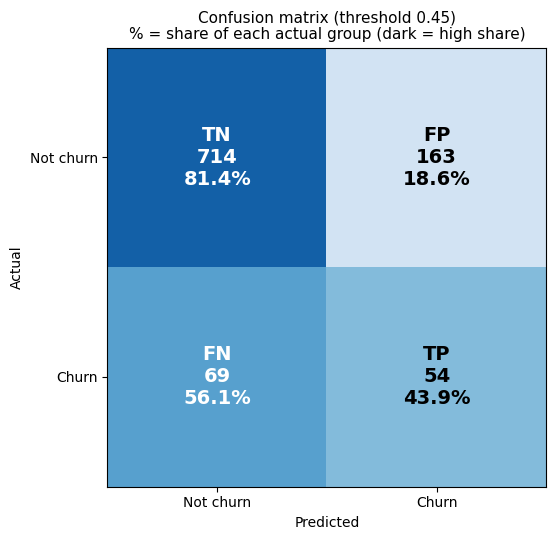

In [8]:
cm = np.array([[tn, fp], [fn, tp]])
row_pct = cm / cm.sum(axis=1, keepdims=True)
cell_names = [["TN", "FP"], ["FN", "TP"]]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cell_names[i][j]}\n{cm[i, j]}\n{row_pct[i, j]:.1%}", ha="center", va="center",
                color="white" if row_pct[i, j] > 0.5 else "black", fontsize=14, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not churn", "Churn"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Not churn", "Churn"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix (threshold {threshold:.2f})\n% = share of each actual group (dark = high share)", fontsize=11)
plt.tight_layout(); plt.show()

## 8. ROC curve
Shows how well the model ranks leavers above stayers across *all* thresholds.

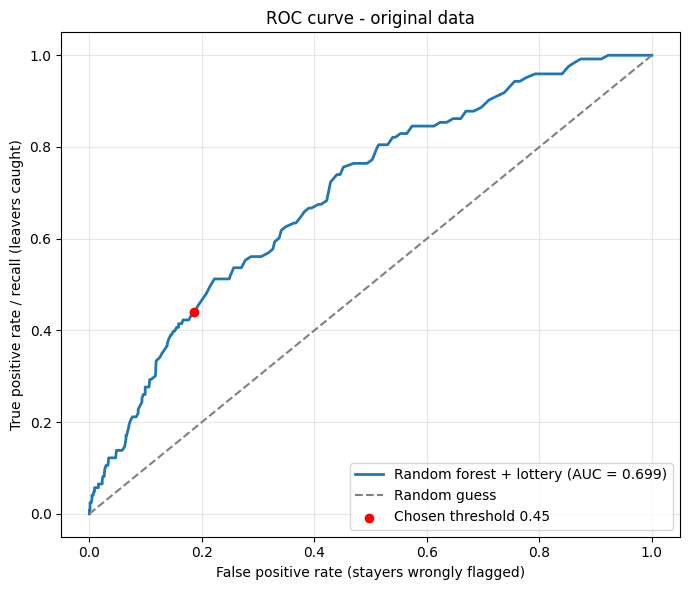

In [9]:
fpr_curve, tpr_curve, _ = roc_curve(y_test, p)
plt.figure(figsize=(7, 6))
plt.plot(fpr_curve, tpr_curve, linewidth=2, label=f"Random forest + lottery (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.scatter([fp / (fp + tn)], [tp / (tp + fn)], color="red", zorder=5, label=f"Chosen threshold {threshold:.2f}")
plt.xlabel("False positive rate (stayers wrongly flagged)")
plt.ylabel("True positive rate / recall (leavers caught)")
plt.title("ROC curve - original data")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 9. Which inputs does the forest use?

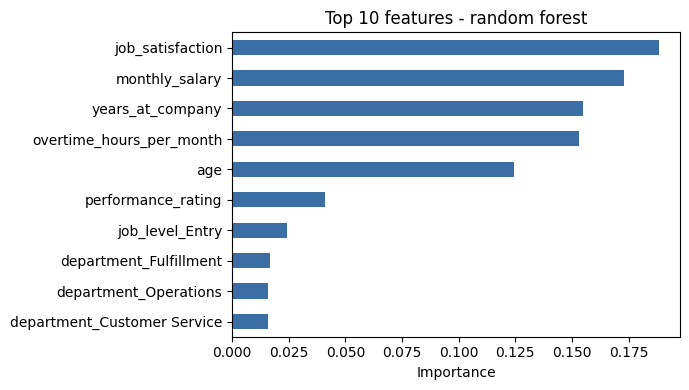

In [10]:
names = [n.split("__", 1)[-1] for n in model.named_steps["preprocessor"].get_feature_names_out()]
imp = pd.Series(model.named_steps["classifier"].feature_importances_, index=names).sort_values(ascending=False)
ax = imp.head(10).iloc[::-1].plot.barh(figsize=(7, 4), color="#3b6ea5")
ax.set_xlabel("Importance"); ax.set_title("Top 10 features - random forest"); plt.tight_layout(); plt.show()

## 10. Diagnostics and stability
These two checks show *why* this model was later replaced.

In [11]:
# Two diagnostics that explain the weaknesses and motivate the next step
auc_train = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, p)
print(f"1) Overfitting check  - AUC on the data it trained on: {auc_train:.3f}  vs  AUC on unseen test data: {auc_test:.3f}")
print(f"   (a big gap means the model memorised noise)")
print(f"2) Probability check  - average predicted churn probability: {p.mean():.1%}  vs  real churn rate: {y_test.mean():.1%}")
print(f"   (the lottery removes stayers during training, so the model over-predicts churn; the threshold is not a real probability)")

1) Overfitting check  - AUC on the data it trained on: 0.988  vs  AUC on unseen test data: 0.699
   (a big gap means the model memorised noise)
2) Probability check  - average predicted churn probability: 29.8%  vs  real churn rate: 12.3%
   (the lottery removes stayers during training, so the model over-predicts churn; the threshold is not a real probability)


In [12]:
# Stability check: repeat the whole pipeline on 5 different splits of ALL the data
aucs, aps = [], []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=7).split(X, y):
    m = clone(model).fit(X.iloc[tr], y.iloc[tr])
    pp = m.predict_proba(X.iloc[te])[:, 1]
    aucs.append(roc_auc_score(y.iloc[te], pp)); aps.append(average_precision_score(y.iloc[te], pp))
print(f"5-fold cross-validation:  ROC AUC {np.mean(aucs):.3f} +/- {np.std(aucs):.3f}   |   PR-AUC {np.mean(aps):.3f} +/- {np.std(aps):.3f}")

5-fold cross-validation:  ROC AUC 0.719 +/- 0.015   |   PR-AUC 0.275 +/- 0.020


## 11. Did the `employee_id` column matter?
It has 5,000 unique values and carries no information. Including it only gives a flexible model more noise to memorise.

In [13]:
def run_rf(drop_id):
    Xa = df.drop(columns=["Churn", termination_col] + (["employee_id"] if drop_id else []))
    Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, y, test_size=0.20, stratify=y, random_state=42)
    nums = Xa_tr.select_dtypes(include="number").columns.tolist(); cats = Xa_tr.select_dtypes(exclude="number").columns.tolist()
    pre = ColumnTransformer([("numeric", numeric_pipeline, nums), ("categorical", categorical_pipeline, cats)])
    m = Pipeline([("preprocessor", pre), ("lottery", RandomUnderSampler(sampling_strategy=0.45, random_state=42)),
                  ("classifier", RandomForestClassifier(n_estimators=200, random_state=42))]).fit(Xa_tr, ya_tr)
    pr = (m.predict_proba(Xa_te)[:, 1] >= 0.45).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(ya_te, pr).ravel()
    return balanced_accuracy_score(ya_te, pr), t_p / (t_p + f_n), t_p / max(t_p + f_p, 1)

rows = [(label, *run_rf(flag)) for label, flag in (("with employee_id", False), ("without employee_id", True))]
pd.DataFrame(rows, columns=["inputs", "balanced accuracy", "recall", "precision"]).round(3)

,inputs,balanced accuracy,recall,precision
0,with employee_id,0.604,0.341,0.264
1,without employee_id,0.627,0.439,0.249


## 12. Summary - what this model achieved and why we moved on

Results on the **original data** (12.3% churn, 123 leavers + 877 stayers in the test set), threshold 0.45:

| Measure | Result |
|---|---|
| Leavers caught (TP) | 54 of 123 (43.9%) |
| False alarms (FP) | 163 |
| Precision | 24.9% (random flagging: 12.3%) |
| Balanced accuracy | 0.627 |
| ROC AUC / PR-AUC | 0.699 / 0.249 |

**Weaknesses that led to the next model**
1. **Overfitting:** the forest scores near-perfectly on its own training data but much lower on unseen data, because fully grown trees memorise noise in a small, noisy, undersampled training set.
2. **Fixed threshold with no meaning:** 0.45 is not a real 45% chance (the lottery inflates probabilities), so the catch rate is an accident of the number chosen.
3. **Noise inputs:** `employee_id` adds nothing and slightly hurts.

**Next:** `02_logistic_regression_lottery` - a simpler, low-variance model, with the threshold chosen from a recall target.